In [31]:
import pandas as pd

trades = pd.read_csv("../data/raw/Allocation_Trades.csv", low_memory=False)
print(trades.shape)
print(trades.columns.tolist())
trades.head()

(488877, 17)
['resource_type', 'origin_state', 'origin_water_system', 'origin_trading_zone_or_WRPA', 'dest_state', 'dest_water_system', 'dest_trading_zone_or_WRPA', 'unit_of_measure', 'quantity_traded', 'net_price', 'price_per_ML', 'date_of_approval', 'regulated_unregulated', 'drainage_division', 'murray_darling_basin_region', 'qld_origin_trading_zone', 'qld_destination_trading_zone']


,resource_type,origin_state,origin_water_system,origin_trading_zone_or_WRPA,dest_state,dest_water_system,dest_trading_zone_or_WRPA,unit_of_measure,quantity_traded,net_price,price_per_ML,date_of_approval,regulated_unregulated,drainage_division,murray_darling_basin_region,qld_origin_trading_zone,qld_destination_trading_zone
0,Surface water,Victoria,VIC Murray (SS2),6 VIC Murray - Dart to Barmah,Victoria,Goulburn (SS6),1A Greater Goulburn,ML,10.0,0,0,15-09-2009,regulated,Murray-Darling Basin,Southern MDB,NaN,NaN
1,Surface water,Victoria,VIC Murray (SS2),7 VIC Murray - Barmah to SA,Victoria,VIC Murray (SS2),7 VIC Murray - Barmah to SA,ML,0.2,0,0,16-09-2009,regulated,Murray-Darling Basin,Southern MDB,NaN,NaN
2,Surface water,Victoria,VIC Murray (SS2),7 VIC Murray - Barmah to SA,Victoria,VIC Murray (SS2),7 VIC Murray - Barmah to SA,ML,2.7,999,370,16-09-2009,regulated,Murray-Darling Basin,Southern MDB,NaN,NaN
3,Surface water,Victoria,VIC Murray (SS2),7 VIC Murray - Barmah to SA,Victoria,VIC Murray (SS2),7 VIC Murray - Barmah to SA,ML,0.5,185,370,16-09-2009,regulated,Murray-Darling Basin,Southern MDB,NaN,NaN
4,Surface water,Victoria,VIC Murray (SS2),6 VIC Murray - Dart to Barmah,Victoria,VIC Murray (SS2),6 VIC Murray - Dart to Barmah,ML,18.0,0,0,16-09-2009,regulated,Murray-Darling Basin,Southern MDB,NaN,NaN


In [32]:
dates = pd.to_datetime(trades["date_of_approval"], dayfirst=True, errors="coerce")
dates.min(), dates.max()

(Timestamp('2008-07-01 00:00:00'), Timestamp('2026-11-09 00:00:00'))

In [33]:
trades["date"] = dates
print("Dates illisibles :", dates.isna().sum())
print("Part des prix à 0 $ :", (trades["price_per_ML"] == 0).mean())
trades["murray_darling_basin_region"].value_counts()

Dates illisibles : 0
Part des prix à 0 $ : 0.44807180538254


murray_darling_basin_region
Southern MDB       423163
Northern MDB        16744
MDB Groundwater     12467
Name: count, dtype: int64

In [34]:
south = trades[
    (trades["murray_darling_basin_region"] == "Southern MDB")
    & (trades["resource_type"] == "Surface water")
    & (trades["price_per_ML"] > 0)
].copy()

print(south.shape)
south["origin_trading_zone_or_WRPA"].value_counts().head(40)

(242908, 18)


origin_trading_zone_or_WRPA
7 VIC Murray - Barmah to SA                                                                                                                                                    59986
1A Greater Goulburn                                                                                                                                                            58277
Murray Irrigation                                                                                                                                                              35935
Murrumbidgee Regulated River Water Source                                                                                                                                      17958
6 VIC Murray - Dart to Barmah                                                                                                                                                  16430
New South Wales Murray Regulated River Water Source / that part of 

In [35]:
def to_region(zone):
    z = str(zone)
    if z.startswith("1A") or z.startswith("2") or z.startswith("3 ") or z == "Broken":
        return "VIC Goulburn-Broken"
    if z.startswith("1B") or z.startswith("4") or z.startswith("5"):
        return "VIC Loddon-Campaspe"
    if z.startswith("6"):
        return "VIC Murray Above"
    if z.startswith("7"):
        return "VIC Murray Below"
    if "upstream of the River Murray at Picnic Point" in z or z == "Murray Irrigation":
        return "NSW Murray Above"
    if "downstream of the River Murray at Picnic Point" in z:
        return "NSW Murray Below"
    if z.startswith("Lower Darling"):
        return "NSW Lower Darling"
    if "Murrumbidgee" in z or "Coleambally" in z:
        return "NSW Murrumbidgee"
    if z.startswith("River Murray Prescribed") or z.startswith("CIT"):
        return "SA Murray"
    return None

south["Region"] = south["origin_trading_zone_or_WRPA"].apply(to_region)
print("Part non classée :", south["Region"].isna().mean())
south["Region"].value_counts()

Part non classée : 0.034527475422793816


Region
VIC Goulburn-Broken    60498
VIC Murray Below       59986
NSW Murray Above       38001
NSW Murrumbidgee       20454
VIC Murray Above       18488
SA Murray              15242
NSW Murray Below       15106
VIC Loddon-Campaspe     6239
NSW Lower Darling        507
Name: count, dtype: int64

In [36]:
south["Year"] = south["date"].dt.year + (south["date"].dt.month >= 7).astype(int)

print(south["price_per_ML"].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]))
print("Part sous 5 $ :", (south["price_per_ML"] < 5).mean())

count    242908.000000
mean        204.549076
std        1701.675046
min           1.000000
1%            1.000000
5%           12.000000
50%         129.000000
95%         550.000000
99%         800.000000
max      620000.000000
Name: price_per_ML, dtype: float64
Part sous 5 $ : 0.01995817346485089


In [37]:
clean = south[(south["price_per_ML"] >= 5) & (south["price_per_ML"] <= 2000)].copy()
print("Ventes gardées :", len(clean), "sur", len(south))

clean["value"] = clean["price_per_ML"] * clean["quantity_traded"]
clean["month"] = clean["date"].dt.month

monthly = clean.groupby(["Year", "Region", "month"]).agg(
    value=("value", "sum"),
    volume=("quantity_traded", "sum"),
    n_trades=("price_per_ML", "size"),
).reset_index()
monthly["P_month"] = monthly["value"] / monthly["volume"]

monthly = monthly[~monthly["month"].isin([6, 7])]

prices = monthly.groupby(["Year", "Region"]).agg(
    P_nominal=("P_month", "mean"),
    n_months=("P_month", "size"),
    n_trades=("n_trades", "sum"),
).reset_index()
prices.head(12)

Ventes gardées : 237808 sur 242908


,Year,Region,P_nominal,n_months,n_trades
0,2009,NSW Murray Above,366.612390,10,1833
1,2009,NSW Murrumbidgee,384.701688,10,2230
2,2009,VIC Goulburn-Broken,346.624471,10,2656
3,2009,VIC Loddon-Campaspe,363.657874,10,191
4,2009,VIC Murray Above,388.712941,10,778
5,2009,VIC Murray Below,379.129610,10,1475
6,2010,NSW Murray Above,191.629734,10,1137
7,2010,NSW Murrumbidgee,173.349261,10,615
8,2010,SA Murray,207.576720,10,456
9,2010,VIC Goulburn-Broken,204.000246,10,2161


In [38]:
cpi_raw = pd.read_excel("../data/raw/abs_cpi_quarterly.xlsx", sheet_name="Data1", index_col=0)

col = [c for c in cpi_raw.columns
       if "index numbers" in str(c).lower()
       and "all groups cpi" in str(c).lower()
       and "australia" in str(c).lower()][0]
print("Colonne choisie :", col)

cpi = cpi_raw[col].iloc[9:].astype(float)
cpi.index = pd.to_datetime(cpi.index)

cpi_year = cpi.groupby(cpi.index.year + (cpi.index.month >= 7).astype(int)).mean()
cpi_year.tail()

Colonne choisie : Index Numbers ;  All groups CPI ;  Australia ;


2023     91.2500
2024     95.0725
2025     97.3900
2026    101.0150
2027    103.6400
Name: Index Numbers ;  All groups CPI ;  Australia ;, dtype: float64

In [39]:
base = cpi_year.loc[2020]   # 2020 = juillet 2019 à juin 2020

prices["CPI"] = prices["Year"].map(cpi_year)
prices["P_real"] = prices["P_nominal"] * base / prices["CPI"]

prices[prices["Year"].isin([2009, 2020, 2026])]

,Year,Region,P_nominal,n_months,n_trades,CPI,P_real
0,2009,NSW Murray Above,366.612390,10,1833,64.3275,457.770373
1,2009,NSW Murrumbidgee,384.701688,10,2230,64.3275,480.357566
2,2009,VIC Goulburn-Broken,346.624471,10,2656,64.3275,432.812469
3,2009,VIC Loddon-Campaspe,363.657874,10,191,64.3275,454.081218
4,2009,VIC Murray Above,388.712941,10,778,64.3275,485.366215
5,2009,VIC Murray Below,379.129610,10,1475,64.3275,473.399994
90,2020,NSW Lower Darling,100.000000,4,6,80.3225,100.000000
91,2020,NSW Murray Above,524.331267,10,996,80.3225,524.331267
92,2020,NSW Murray Below,651.551751,10,851,80.3225,651.551751
93,2020,NSW Murrumbidgee,541.137227,10,958,80.3225,541.137227


In [40]:
abares = pd.read_excel("../data/raw/abares_mdb_supply_2021.xlsx", sheet_name="Supply")[["Year", "Region", "P"]]

check = prices.merge(abares, on=["Year", "Region"], how="inner")
print("Paires région-année en commun :", len(check))
print("Corrélation :", check["P_real"].corr(check["P"]))
print("Écart médian (BOM / ABARES - 1) :", (check["P_real"] / check["P"]).median() - 1)

Paires région-année en commun : 108
Corrélation : 0.9886393392924514
Écart médian (BOM / ABARES - 1) : -0.0040119835573118046


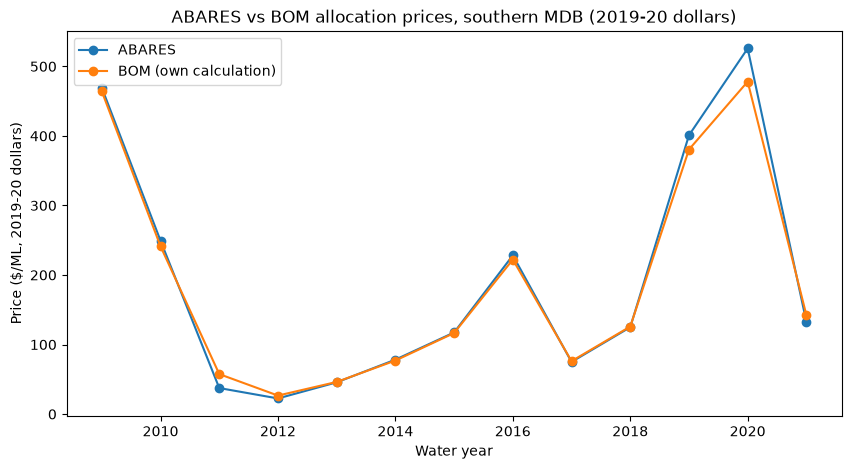

In [41]:
by_year = check.groupby("Year")[["P", "P_real"]].mean()

ax = by_year.plot(marker="o", figsize=(10, 5),
                  title="ABARES vs BOM allocation prices, southern MDB (2019-20 dollars)")
ax.set_ylabel("Price ($/ML, 2019-20 dollars)")
ax.set_xlabel("Water year")
ax.legend(["ABARES", "BOM (own calculation)"])
ax.figure.savefig("../figures/overlap_check.png", dpi=150, bbox_inches="tight")

In [42]:
prices.to_csv("../data/processed/bom_prices.csv", index=False)

**Overlap check (2009-2021):** Following the ABARES method (monthly volume-weighted
prices averaged over August to May, converted to 2019-20 dollars with the ABS CPI),
BOM prices match ABARES closely: correlation 0.99 across 108 region-years, median
gap -0.4%. The largest gap is in 2019-20 (BOM about 9% lower). The BOM series can
therefore be used to extend the ABARES data to 2026.

In [46]:
import requests, io

EMAIL = "imad.ramdani.im@gmail.com"

points = {
    "NSW Murray Above": (-35.55, 144.95),     # Deniliquin
    "NSW Murray Below": (-35.10, 144.05),     # Moulamein
    "NSW Murrumbidgee": (-34.30, 146.05),     # Griffith
    "NSW Lower Darling": (-32.40, 142.40),    # Menindee
    "SA Murray": (-34.45, 140.55),            # Loxton
    "VIC Goulburn-Broken": (-36.40, 145.40),  # Shepparton
    "VIC Loddon-Campaspe": (-36.35, 144.70),  # Rochester
    "VIC Murray Above": (-35.90, 145.65),     # Cobram
    "VIC Murray Below": (-34.20, 142.15),     # Mildura
}

url = "https://www.longpaddock.qld.gov.au/cgi-bin/silo/DataDrillDataset.php"
frames = []
for region, (lat, lon) in points.items():
    params = {"lat": lat, "lon": lon, "start": "20080701", "finish": "20261031",
              "format": "csv", "comment": "R", "username": EMAIL, "password": "apirequest"}
    r = requests.get(url, params=params, timeout=120)
    df = pd.read_csv(io.StringIO(r.text))
    df["Region"] = region
    frames.append(df)
    print(region, len(df))

rain = pd.concat(frames)
rain.to_csv("../data/raw/silo_rainfall_daily.csv", index=False)
rain.head()

NSW Murray Above 6697
NSW Murray Below 6697
NSW Murrumbidgee 6697
NSW Lower Darling 6697
SA Murray 6697
VIC Goulburn-Broken 6697
VIC Loddon-Campaspe 6697
VIC Murray Above 6697
VIC Murray Below 6697


,latitude,longitude,YYYY-MM-DD,daily_rain,daily_rain_source,metadata,Region
0,-35.55,144.95,2008-07-01,1.7,25,elevation= 95.0 m,NSW Murray Above
1,-35.55,144.95,2008-07-02,0.2,25,reference=R,NSW Murray Above
2,-35.55,144.95,2008-07-03,0.0,25,extracted=20261112,NSW Murray Above
3,-35.55,144.95,2008-07-04,0.0,25,dataset=BoM Only,NSW Murray Above
4,-35.55,144.95,2008-07-05,0.0,25,Please read our web site for information about...,NSW Murray Above
